# The FNO in 2D: a 64 × 64 velocity field, every tensor drawn

The 1D notebook ([`fno_explained.ipynb`](fno_explained.ipynb)) shows every number of a Fourier Neural Operator on a
line of 32 points. This one does the same for a **2D flow on a 64 × 64 grid**, the setting of the FNO paper's
Navier–Stokes experiments (Li et al. 2021, [arXiv:2010.08895](https://arxiv.org/abs/2010.08895), Sec. 5.3):

$$
\underbrace{64\times64\times4}_{[u,\,v,\,x,\,y]}
\;\xrightarrow{\;P\;}\; 64\times64\times8
\;\xrightarrow{\;4\ \text{Fourier layers}\;}\; 64\times64\times8
\;\xrightarrow{\;Q\;}\; \underbrace{64\times64\times2}_{[u,\,v]\text{ later}}
$$

**Plan**

0. **Fourier and convolution from scratch, on 8 numbers.** What "turning a signal into waves" means, why an
   "upstream" rule is a convolution, and why a convolution becomes one multiplication per wave.
1. The flow: 2D viscous Burgers, a velocity field that carries and smooths itself.
2. The input tensor $64\times64\times4$, also written as the $4096\times4$ matrix of GNS style.
3. Lift $P$: $64\times64\times4 \to 64\times64\times8$, with a worked pixel.
4. One Fourier layer, stage by stage: 2D FFT of each channel, the kept low modes, the spectral weights $R$, inverse
   FFT, pointwise $W$, GELU. Worked numbers at each step.
5. Project $Q$: $64\times64\times8 \to 64\times64\times2$.
6. Training, an explorer with sliders, and predictions vs the truth.

In [1]:
import sys
sys.path.insert(0, "..")

import time
import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

from src.physics2d import Burgers2DParams, make_dataset, wavenumbers
from src import model2d as fno2d
from src.training import relative_l2, train, evaluate
from src import visualize as viz

plt.rcParams["figure.dpi"] = 100

## 0. Fourier and convolution from scratch, on 8 numbers

### 0a. "Converting to Fourier" = describing the same numbers as a sum of waves

Take the velocity at 8 fixed points on a loop (point 7 is next to point 0): a bump at point 3.

$$
v = [0,\ 0,\ 1,\ 3,\ 1,\ 0,\ 0,\ 0].
$$

These 8 numbers can be written **exactly** as a sum of waves
$v_j = \hat v_0 + 2\,\mathrm{Re}\sum_{k=1}^{3}\hat v_k e^{2\pi i k j/8} + \hat v_4 (-1)^j$: a constant ($k=0$),
one wiggle around the loop ($k=1$), two wiggles ($k=2$), three, four. Each $\hat v_k$ is one complex number: its
size is the wave's amplitude, its angle is where the wave's peak sits. Nothing is approximated. It is the same
information, organised by "how wiggly" instead of "where".

For an image the waves ripple in both directions, $e^{2\pi i (k_x x + k_y y)}$, and there is one coefficient per pair
$(k_x, k_y)$.

In [2]:
v = np.array([0, 0, 1, 3, 1, 0, 0, 0.])
j = np.arange(8)
v_hat = np.fft.rfft(v, norm="forward")             # 5 complex numbers, k = 0..4
print("v_hat_k =", np.round(v_hat, 3))
waves = [(v_hat[k] * np.exp(2j * np.pi * k * j / 8)).real * (1 if k in (0, 4) else 2) for k in range(5)]
for k, wv in enumerate(waves):
    print(f"wave k={k}: {np.round(wv, 3)}")
print("sum of the waves =", np.round(sum(waves), 3), "  (the original v)")

v_hat_k = [ 0.625+0.j    -0.39 -0.39j   0.   +0.375j  0.14 -0.14j  -0.125+0.j   ]
wave k=0: [0.625 0.625 0.625 0.625 0.625 0.625 0.625 0.625]
wave k=1: [-0.78  -0.     0.78   1.104  0.78   0.    -0.78  -1.104]
wave k=2: [ 0.   -0.75 -0.    0.75  0.   -0.75 -0.    0.75]
wave k=3: [ 0.28  -0.    -0.28   0.396 -0.28  -0.     0.28  -0.396]
wave k=4: [-0.125  0.125 -0.125  0.125 -0.125  0.125 -0.125  0.125]
sum of the waves = [ 0. -0.  1.  3.  1. -0.  0.  0.]   (the original v)


### 0b. An "upstream" rule is a convolution

Suppose the flow carries things to the right, and the new value at a point is a bit of itself plus some of what was
just upstream:

$$
\text{out}_j = 0.5\,v_j + 0.3\,v_{j-1} + 0.2\,v_{j-2} = \sum_s \kappa_s\, v_{j-s},\qquad \kappa = [0.5,\ 0.3,\ 0.2,\ 0,\dots].
$$

The weights depend only on the **offset** $s$ (how far upstream), not on where $j$ is: the same three weights slide
along the line. "The same weighted-sum rule at every point" is the definition of a **convolution**. An FNO layer's
global part is exactly this, $(\mathcal K v)(x) = \int \kappa(x - y)\, v(y)\, dy$, with $\kappa$ learned and
reaching the **whole** domain. Done directly that is $N$ weights for each of $N$ points: $N^2$ work, about 16 million
for a 64 × 64 grid.

### 0c. In wave space a convolution is one multiplication per wave

A rule that is the same everywhere cannot turn a $k=1$ wave into a $k=2$ wave: a wave goes in, the same wave comes
out, scaled and shifted. So

$$
\widehat{\text{out}}_k = \hat\kappa_k\cdot \hat v_k\qquad(\text{convolution theorem}).
$$

Multiply each wave by its own number, add the waves back up, and you get the sliding sum. The FNO learns the numbers
$\hat\kappa_k$ directly (they are $R$), for the lowest waves only, and lets each one be a $d\times d$ matrix so it can
mix channels too.

point 4 by hand: 0.5*v4 + 0.3*v3 + 0.2*v2 = 1.5999999999999999
sliding weighted sum          : [0.  0.  0.5 1.8 1.6 0.9 0.2 0. ]
multiplier per wave |kappa_hat|: [1.    0.823 0.424 0.288 0.4  ]
multiply each wave, add back  : [0.  0.  0.5 1.8 1.6 0.9 0.2 0. ]


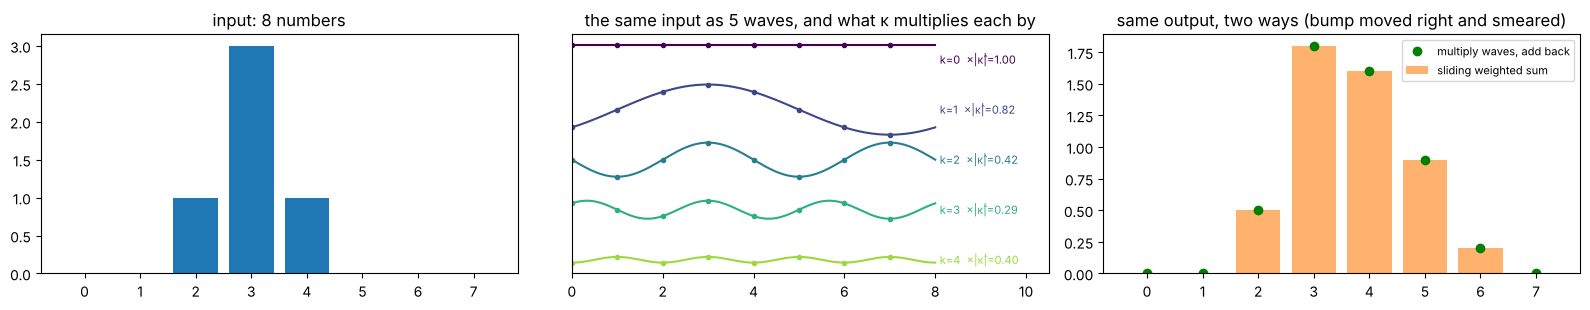

In [3]:
kappa = np.array([0.5, 0.3, 0.2, 0, 0, 0, 0, 0])
direct = np.array([sum(kappa[s] * v[(i - s) % 8] for s in range(8)) for i in range(8)])
kappa_hat = np.fft.rfft(kappa)                     # what the rule does to each wave
via_waves = np.fft.irfft(v_hat * kappa_hat, n=8, norm="forward")
print("point 4 by hand: 0.5*v4 + 0.3*v3 + 0.2*v2 =", 0.5 * 1 + 0.3 * 3 + 0.2 * 1)
print("sliding weighted sum          :", np.round(direct, 3))
print("multiplier per wave |kappa_hat|:", np.round(np.abs(kappa_hat), 3))
print("multiply each wave, add back  :", np.round(via_waves, 3))

fig, ax = plt.subplots(1, 3, figsize=(16, 3.2))
ax[0].bar(j, v, color="tab:blue"); ax[0].set_title("input: 8 numbers"); ax[0].set_xticks(j)
cols = plt.cm.viridis(np.linspace(0, 0.85, 5)); xf = np.linspace(0, 8, 300)
for k in range(5):
    m = 1 if k in (0, 4) else 2
    ax[1].plot(xf, (v_hat[k] * np.exp(2j * np.pi * k * xf / 8)).real * m - 2.2 * k, color=cols[k])
    ax[1].plot(j, waves[k] - 2.2 * k, "o", ms=3, color=cols[k])
    ax[1].text(8.1, -2.2 * k, f"k={k}  ×|κ̂|={abs(kappa_hat[k]):.2f}", fontsize=8, va="center", color=cols[k])
ax[1].set_xlim(0, 10.5); ax[1].set_yticks([]); ax[1].set_title("the same input as 5 waves, and what κ multiplies each by")
ax[2].bar(j, direct, color="tab:orange", alpha=0.6, label="sliding weighted sum")
ax[2].plot(j, via_waves, "go", label="multiply waves, add back"); ax[2].legend(fontsize=8); ax[2].set_xticks(j)
ax[2].set_title("same output, two ways (bump moved right and smeared)")
plt.tight_layout(); plt.show()

That is the whole idea of the Fourier layer. Everything below is this, in 2D, for 8 channels at once.

## 1. The flow: 2D viscous Burgers

A velocity field $\mathbf u = (u, v)$ on the periodic unit square carries itself along and is smoothed by viscosity:

$$
\partial_t \mathbf u + (\mathbf u\cdot\nabla)\mathbf u = \nu\,\Delta \mathbf u,\qquad \nu = 0.02 .
$$

The points of the grid are **fixed** places in space (the fluid moves past them). The operator to learn maps the
velocity everywhere at $t = 0$ to the velocity everywhere at $t = 0.5$. The reference solver is pseudo-spectral
(`src/physics2d.py`); 2200 random initial fields are solved, 2000 for training and 200 for testing.

solved 2200 flows in 134.8 s;  a: (2200, 64, 64, 2)  u: (2200, 64, 64, 2)


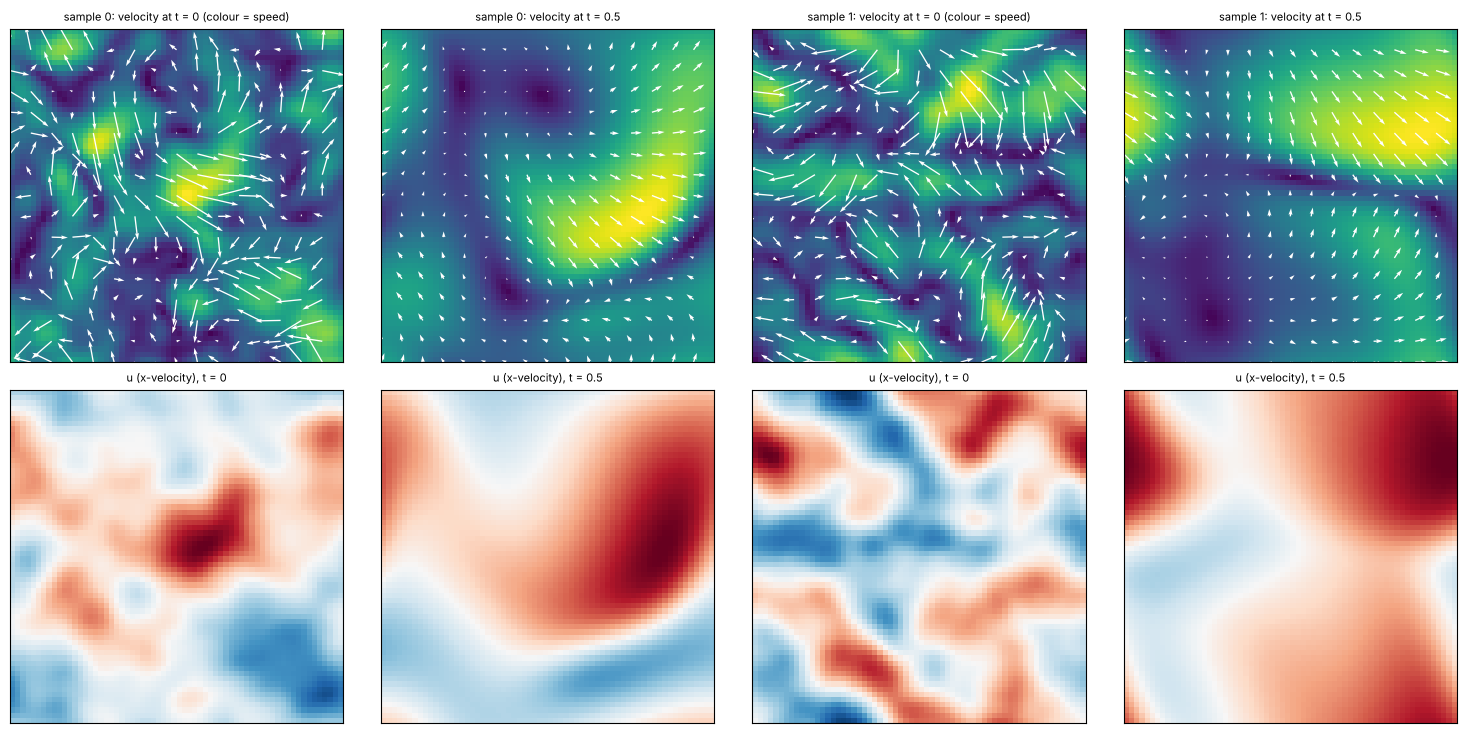

In [4]:
phys = Burgers2DParams()                  # nu = 0.02, t = 0.5, 64 x 64, dt = 2e-3
t0 = time.time()
data = jax.block_until_ready(make_dataset(jax.random.PRNGKey(0), 2200, phys))
print(f"solved 2200 flows in {time.time() - t0:.1f} s;  a: {data['a'].shape}  u: {data['u'].shape}")
a_train, u_train = data["a"][:2000], data["u"][:2000]
a_test, u_test = data["a"][2000:], data["u"][2000:]
n = phys.n

def show_flow(ax, w, title):
    speed = np.linalg.norm(np.asarray(w), axis=-1)
    viz.image(ax, speed, title, cmap="viridis")
    s = 4; X, Y = np.meshgrid(np.arange(0, n, s) / n, np.arange(0, n, s) / n, indexing="ij")
    ax.quiver(X, Y, w[::s, ::s, 0], w[::s, ::s, 1], color="white", scale=12, width=0.004)

fig, axes = plt.subplots(2, 4, figsize=(15, 7.4))
for c, i in enumerate([0, 1]):
    show_flow(axes[0, 2 * c], a_test[i], f"sample {i}: velocity at t = 0 (colour = speed)")
    show_flow(axes[0, 2 * c + 1], u_test[i], f"sample {i}: velocity at t = 0.5")
    viz.image(axes[1, 2 * c], a_test[i][..., 0], "u (x-velocity), t = 0")
    viz.image(axes[1, 2 * c + 1], u_test[i][..., 0], "u (x-velocity), t = 0.5")
plt.tight_layout(); plt.show()

In half a time unit the small eddies are smoothed away (viscosity) and the large-scale flow is carried along by
itself (advection). Where fast fluid runs into slow fluid the velocity changes steeply (the edges of the bright
regions). The carrying-along is nonlinear: how far something moves depends on the velocity itself. That is the part
the network has to learn.

## 2. The input tensor: $64\times64\times4$, or a $4096\times4$ matrix

At every grid point the input has 4 numbers: the two velocities $u, v$ and the two coordinates $x, y$. As a tensor
that is $64\times64\times4$: four images. Flattening the grid gives the GNS-style matrix with one row per point,
$4096 \times 4$. Both views hold the same numbers. The FNO keeps the image layout because the FFT needs to know which
point is next to which.

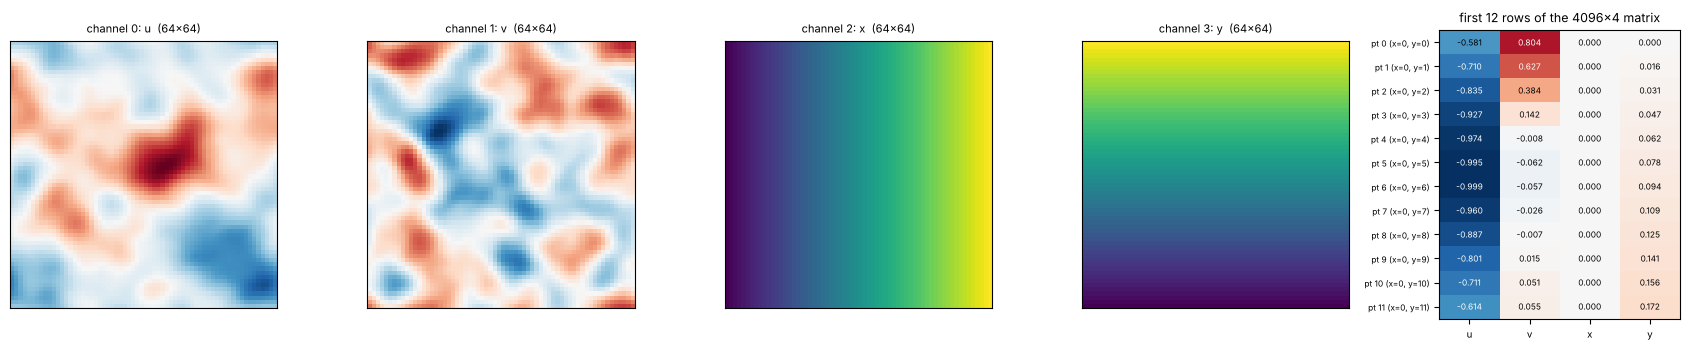

In [5]:
X_in = np.asarray(fno2d.make_input(a_test[0]))
fig, axes = plt.subplots(1, 5, figsize=(17, 3.6), gridspec_kw=dict(width_ratios=[1, 1, 1, 1, 0.9]))
for c, name in enumerate(["u", "v", "x", "y"]):
    viz.image(axes[c], X_in[..., c], f"channel {c}: {name}  (64×64)", cmap="RdBu_r" if c < 2 else "viridis")
rows = X_in.reshape(-1, 4)[:12]
viz.matrix(axes[4], rows, [f"pt {i} (x={i // n}, y={i % n})" for i in range(12)], ["u", "v", "x", "y"],
           "first 12 rows of the 4096×4 matrix", fmt="{:.3f}")
plt.tight_layout(); plt.show()

## 3. Lift $P$: from 4 numbers to 8 channels at every point

$P$ is a $4\times8$ matrix plus a bias. **The same** $P$ multiplies the 4-vector at every one of the 4096 points
(a $1\times1$ convolution), so after this step each point has 8 numbers and no point has seen any other yet. The
result is 8 images, one per channel.

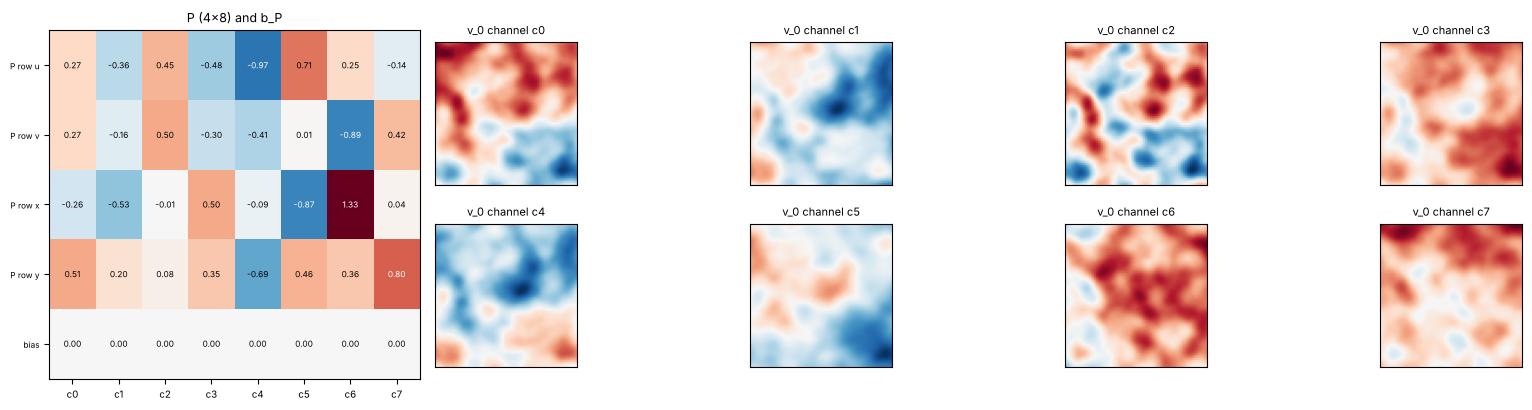

pixel (x=20, y=40): [u, v, x, y] = [ 0.2495 -1.0115  0.3125  0.625 ]
v_0 there by hand  = [u v x y] @ P + b = [ 0.032  0.029 -0.344  0.565 -0.289  0.178  1.602  0.05 ]
v_0 from the model                     = [ 0.032  0.029 -0.344  0.565 -0.289  0.178  1.602  0.05 ]


In [6]:
cfg = fno2d.FNO2DConfig(width=8, modes=8, layers=4, proj_hidden=32)
params0 = fno2d.init_params(jax.random.PRNGKey(1), cfg)
tr0 = fno2d.apply_with_trace(params0, a_test[0])
W_P, b_P = (np.asarray(p) for p in params0["P"])

fig = plt.figure(figsize=(17, 4.2))
gs = fig.add_gridspec(2, 9, width_ratios=[2.6] + [1] * 8)
viz.matrix(fig.add_subplot(gs[:, 0]), np.r_[W_P, b_P[None]], ["P row u", "P row v", "P row x", "P row y", "bias"],
           viz.channel_labels(8), "P (4×8) and b_P")
for c in range(8):
    viz.image(fig.add_subplot(gs[c // 4, 1 + 2 * (c % 4)]), tr0.lifted[..., c], f"v_0 channel c{c}")
plt.tight_layout(); plt.show()

px, py = 20, 40
row = X_in[px, py]
print(f"pixel (x={px}, y={py}): [u, v, x, y] = {np.round(row, 4)}")
print(f"v_0 there by hand  = [u v x y] @ P + b = {np.round(row @ W_P + b_P, 3)}")
print(f"v_0 from the model                     = {np.round(np.asarray(tr0.lifted[px, py]), 3)}")

## 4. One Fourier layer, stage by stage

### 4a. The 2D FFT of one channel

Take channel c0 of $v_0$: a $64\times64$ image. The 2D FFT rewrites it as a sum of 2D waves
$e^{2\pi i(k_x x + k_y y)}$, one complex coefficient per pair $(k_x, k_y)$. Because the image is real, the
$k_y<0$ half is redundant, so `rfft2` keeps $k_x = -32..31$ and $k_y = 0..32$: a $64\times33$ grid of coefficients.
Each channel is transformed **separately**: the FFT runs over space, never across channels.

Below: four of the 2D waves, the channel image, and the size of every coefficient (log scale). The energy sits near
$(0, 0)$: smooth images are mostly slow waves. (The bright lines along $k_x = 0$ and $k_y = 0$ come from the $x$ and
$y$ input channels: on a periodic domain a ramp from 0 to 1 jumps back at the edge, and a jump needs waves of every
frequency.)

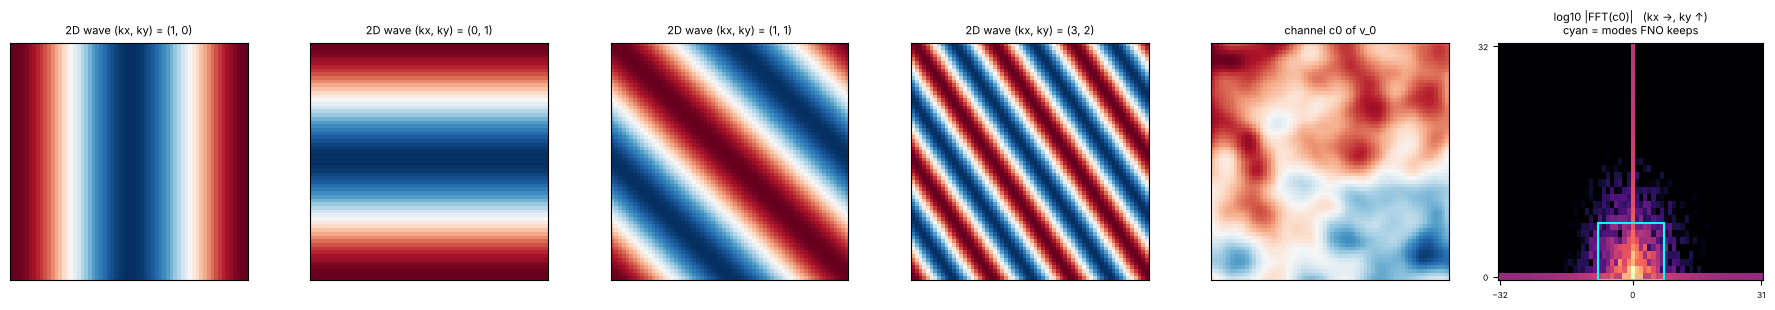

coefficient (kx=1, ky=0) of channel c0 by hand: mean of c0(x,y)·e^(-2πi·x) = 0.0096-0.0399j
from jnp.fft.rfft2(norm='forward')                               = 0.0096-0.0399j


In [7]:
xs = np.arange(n) / n
XX, YY = np.meshgrid(xs, xs, indexing="ij")
fig, axes = plt.subplots(1, 6, figsize=(18, 3.2))
for ax, (kx, ky) in zip(axes[:4], [(1, 0), (0, 1), (1, 1), (3, 2)]):
    viz.image(ax, np.cos(2 * np.pi * (kx * XX + ky * YY)), f"2D wave (kx, ky) = ({kx}, {ky})")
viz.image(axes[4], tr0.lifted[..., 0], "channel c0 of v_0")
viz.spectrum_image(axes[5], tr0.v_hat[0][..., 0], cfg.modes, "log10 |FFT(c0)|   (kx →, ky ↑)\ncyan = modes FNO keeps")
plt.tight_layout(); plt.show()

c0 = np.asarray(tr0.lifted[..., 0])
by_hand = (c0 * np.exp(-2j * np.pi * (1 * XX + 0 * YY) * n / n)).mean()
print(f"coefficient (kx=1, ky=0) of channel c0 by hand: mean of c0(x,y)·e^(-2πi·x) = {by_hand:.4f}")
print(f"from jnp.fft.rfft2(norm='forward')                               = {complex(tr0.v_hat[0][1, 0, 0]):.4f}")

### 4b. Keep only the low modes, multiply each by its own $8\times8$ complex matrix $R$

FNO keeps $|k_x| < 8$ and $k_y < 8$ (the cyan box): $16\times8 = 128$ of the $64\times33 = 2112$ coefficients per
channel, and sets the rest to zero. In memory $k_x = -8..-1$ sit at the end of the array, so the box is stored as two
$8\times8$ corner blocks (paper code: `weights1`, `weights2`).

For every kept mode, the 8 channel coefficients there (a row of 8 complex numbers) are multiplied by that mode's
own $8\times8$ complex matrix $R[k_x, k_y]$. Channels mix; different modes never mix (that is the convolution, 0c).
Worked example: mode $(k_x, k_y) = (1, 0)$, output channel c0.

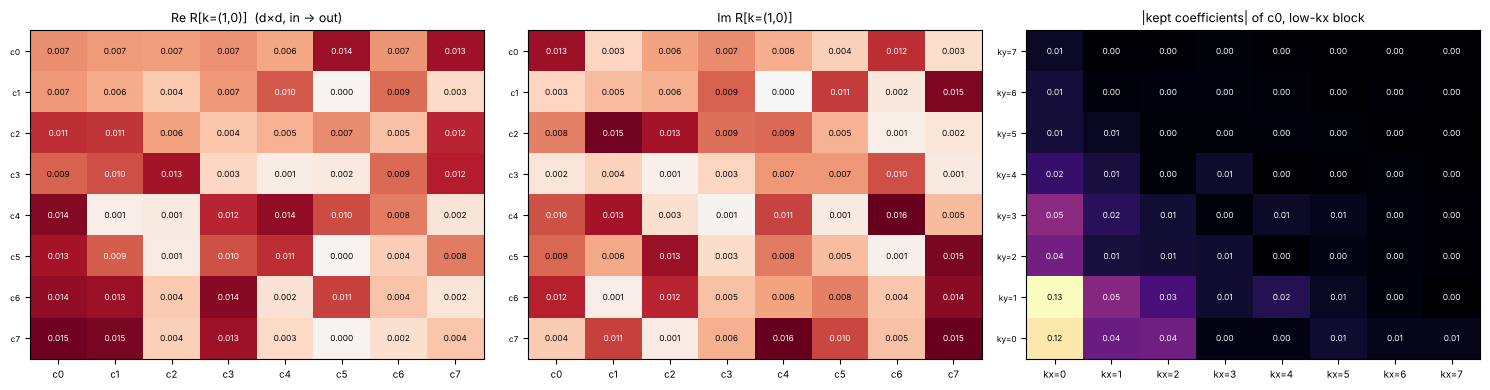

v_hat at (1,0), 8 channels: [ 0.01 -0.04j   0.016-0.077j  0.018+0.002j  0.001+0.086j  0.033+0.008j
 -0.047-0.168j -0.125+0.16j   0.055+0.031j]
(R v_hat) at (1,0), c0 by hand = sum_i v_hat_i · R[i, c0] = -0.0007-0.0004j
from the model                                         = -0.0007-0.0004j


In [8]:
L1 = params0["layers"][0]
R = np.asarray(L1["R_re"]) + 1j * np.asarray(L1["R_im"])        # (2, 8, 8, d, d)
kept = np.asarray(tr0.v_hat_kept[0])                             # (2, 8, 8, d)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
viz.complex_weights(axes[0], axes[1], R[0, 1, 0], "(1,0)")
viz.matrix(axes[2], np.abs(kept[0, :, :, 0]).T[::-1], [f"ky={i}" for i in range(7, -1, -1)],
           [f"kx={i}" for i in range(8)], "|kept coefficients| of c0, low-kx block", cmap="magma")
plt.tight_layout(); plt.show()

row = kept[0, 1, 0]                                               # 8 channels at mode (1, 0)
print("v_hat at (1,0), 8 channels:", np.round(row, 3))
print(f"(R v_hat) at (1,0), c0 by hand = sum_i v_hat_i · R[i, c0] = {(row * R[0, 1, 0][:, 0]).sum():.4f}")
print(f"from the model                                         = {complex(tr0.Rv_hat[0][0, 1, 0, 0]):.4f}")

### 4c. Inverse FFT, the local path $W$, and the activation

The 128 modified modes per channel go back in place (everything else zero) and the inverse FFT returns 8 smooth
$64\times64$ images: the **global** path $\mathcal K v$, where every pixel was influenced by every other pixel. In
parallel the **local** path applies one $8\times8$ matrix $W$ at each pixel (it keeps the sharp, pixel-level detail
that the 8-mode cut throws away). They are added and passed through GELU.

The figure shows the whole layer: one row per stage, one column per channel.

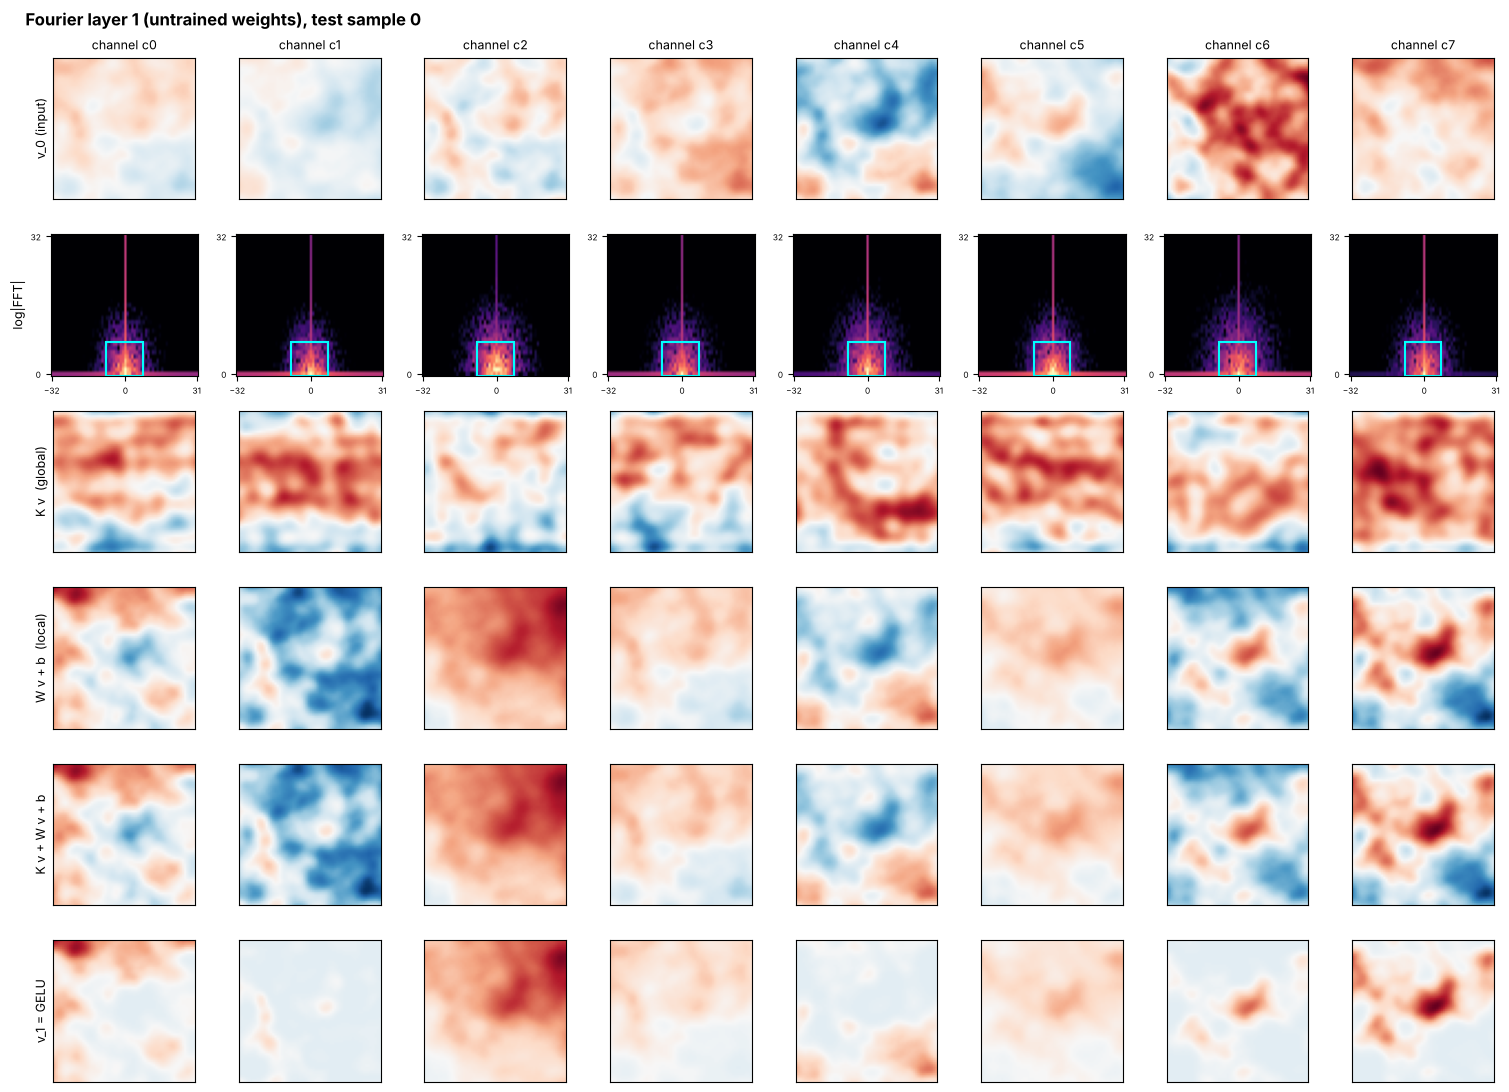

pixel (20,40), channel c0:  K v = 0.0238,  W v + b = -0.0948
sum = -0.0710,  GELU(sum) = -0.0335   (model: -0.0335)


In [9]:
viz.layer_flow_2d(tr0, 0, cfg.modes, "Fourier layer 1 (untrained weights), test sample 0")
plt.show()

Wm, bm = np.asarray(L1["W"]), np.asarray(L1["b"])
loc = np.asarray(tr0.lifted[px, py]) @ Wm[:, 0] + bm[0]
pre = float(tr0.spectral[0][px, py, 0]) + loc
print(f"pixel ({px},{py}), channel c0:  K v = {float(tr0.spectral[0][px, py, 0]):.4f},  W v + b = {loc:.4f}")
print(f"sum = {pre:.4f},  GELU(sum) = {float(jax.nn.gelu(pre)):.4f}   (model: {float(tr0.v[0][px, py, 0]):.4f})")

## 5. Project $Q$: back to two velocities per point

After 4 layers, a small MLP applied at every pixel ($8\to32\to2$) turns the 8 channels into $(u, v)$ at $t = 0.5$.
Untrained, the output is noise; section 6 trains it.

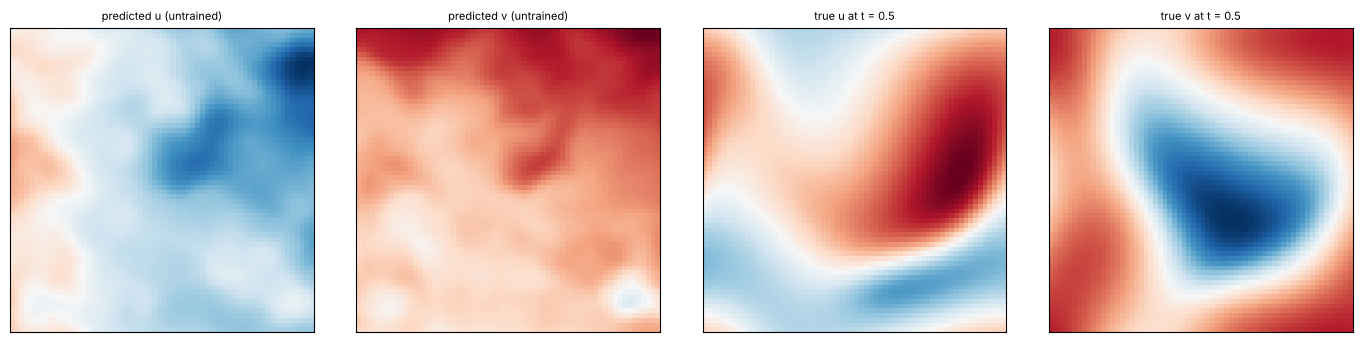

parameters: 66218  (almost all in R: 4 layers × 2 blocks × 8 × 8 modes × 8 × 8 channels × re/im)


In [10]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.4))
viz.image(axes[0], tr0.output[..., 0], "predicted u (untrained)")
viz.image(axes[1], tr0.output[..., 1], "predicted v (untrained)")
viz.image(axes[2], u_test[0][..., 0], "true u at t = 0.5")
viz.image(axes[3], u_test[0][..., 1], "true v at t = 0.5")
plt.tight_layout(); plt.show()
n_params = sum(int(np.prod(p.shape)) for p in jax.tree_util.tree_leaves(params0))
print(f"parameters: {n_params}  (almost all in R: 4 layers × 2 blocks × 8 × 8 modes × 8 × 8 channels × re/im)")

## 6. Train, explore, compare

Loss: relative $L^2$ over both velocity components (as in the 1D notebook). 3000 Adam steps on mini-batches of 16;
about 3 minutes on a laptop CPU (solving the 2200 flows above takes another 2-3).

step   500   relative L2 (train batch) = 0.1400


step  1000   relative L2 (train batch) = 0.1119


step  1500   relative L2 (train batch) = 0.0883


step  2000   relative L2 (train batch) = 0.0711


step  2500   relative L2 (train batch) = 0.0725


step  3000   relative L2 (train batch) = 0.0721
trained in 148 s


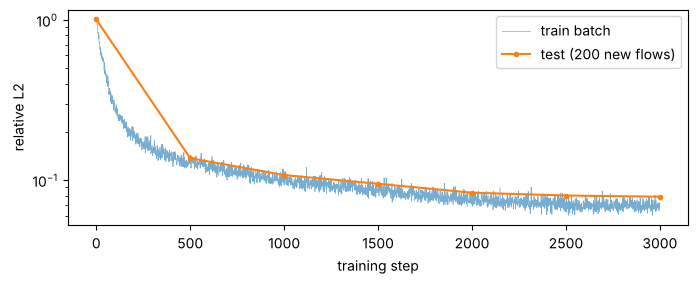

final test relative L2: 0.079


In [11]:
t0 = time.time()
params, snapshots, snap_steps, losses = train(params0, a_train, u_train, n_steps=3000, batch_size=16, lr=5e-3,
                                              snapshot_every=500, log_every=500, apply_fn=fno2d.apply)
print(f"trained in {time.time() - t0:.0f} s")
test_err = [evaluate(p, a_test, u_test, apply_fn=fno2d.apply) for p in snapshots]
fig, ax = plt.subplots(figsize=(8, 2.8))
ax.semilogy(losses, lw=0.5, alpha=0.6, label="train batch")
ax.semilogy(snap_steps, test_err, "o-", ms=3, label="test (200 new flows)")
ax.set_xlabel("training step"); ax.set_ylabel("relative L2"); ax.legend(); plt.show()
print(f"final test relative L2: {test_err[-1]:.3f}")

### Explorer

Sliders: **training step** (weight snapshot), **test sample**, **layer**; press **Run Interact** to draw (each
redraw is about 50 images, so it does not redraw on every slider tick). The top row compares prediction and truth;
below is the chosen layer, stage by stage and channel by channel (the same picture as 4c). Try dragging the training
step from 0: the channel images go from noise to recognisable pieces of the flow.

In [12]:
import ipywidgets as w

def explore(snapshot, sample, layer):
    tr = fno2d.apply_with_trace(snapshots[snapshot], a_test[sample])
    err = float(relative_l2(tr.output.ravel(), u_test[sample].ravel()))
    fig, axes = plt.subplots(1, 5, figsize=(16, 3.2))
    show_flow(axes[0], a_test[sample], "input at t = 0")
    for c, name in enumerate("uv"):
        vmax = float(np.abs(u_test[sample][..., c]).max())
        viz.image(axes[1 + 2 * c], u_test[sample][..., c], f"true {name}, t = 0.5", vmax=vmax)
        viz.image(axes[2 + 2 * c], tr.output[..., c], f"FNO {name}", vmax=vmax)
    fig.suptitle(f"training step {snap_steps[snapshot]}, sample {sample}: relative L2 = {err:.3f}", x=0.02, ha="left")
    plt.tight_layout(); plt.show()
    viz.layer_flow_2d(tr, layer - 1, cfg.modes, f"layer {layer}"); plt.show()

w.interact_manual(explore,
           snapshot=w.IntSlider(min=0, max=len(snapshots) - 1, value=len(snapshots) - 1, description="train step #"),
           sample=w.IntSlider(min=0, max=len(a_test) - 1, value=0, description="test sample"),
           layer=w.IntSlider(min=1, max=cfg.layers, value=1, description="layer"));

interactive(children=(IntSlider(value=6, description='train step #', max=6), IntSlider(value=0, description='t…

### Static version: trained network, test sample 0, layers 1 and 4

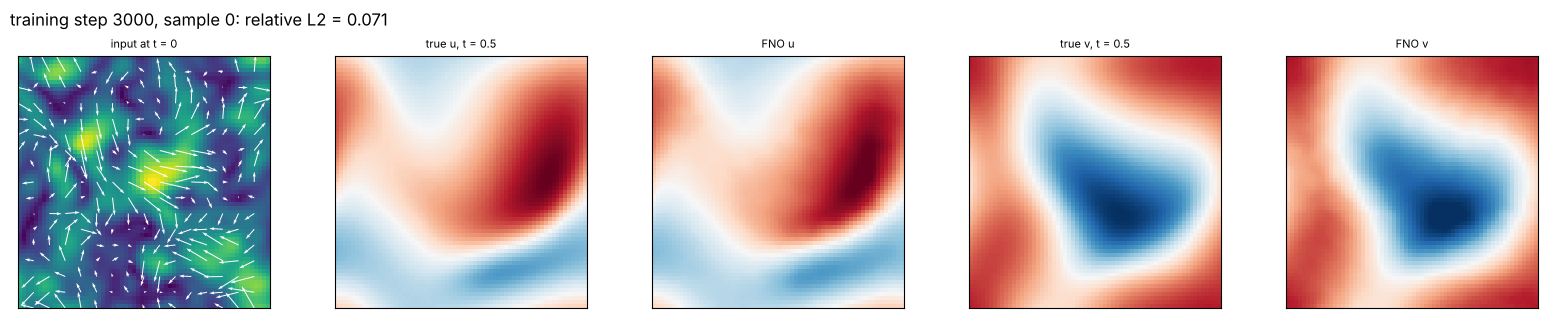

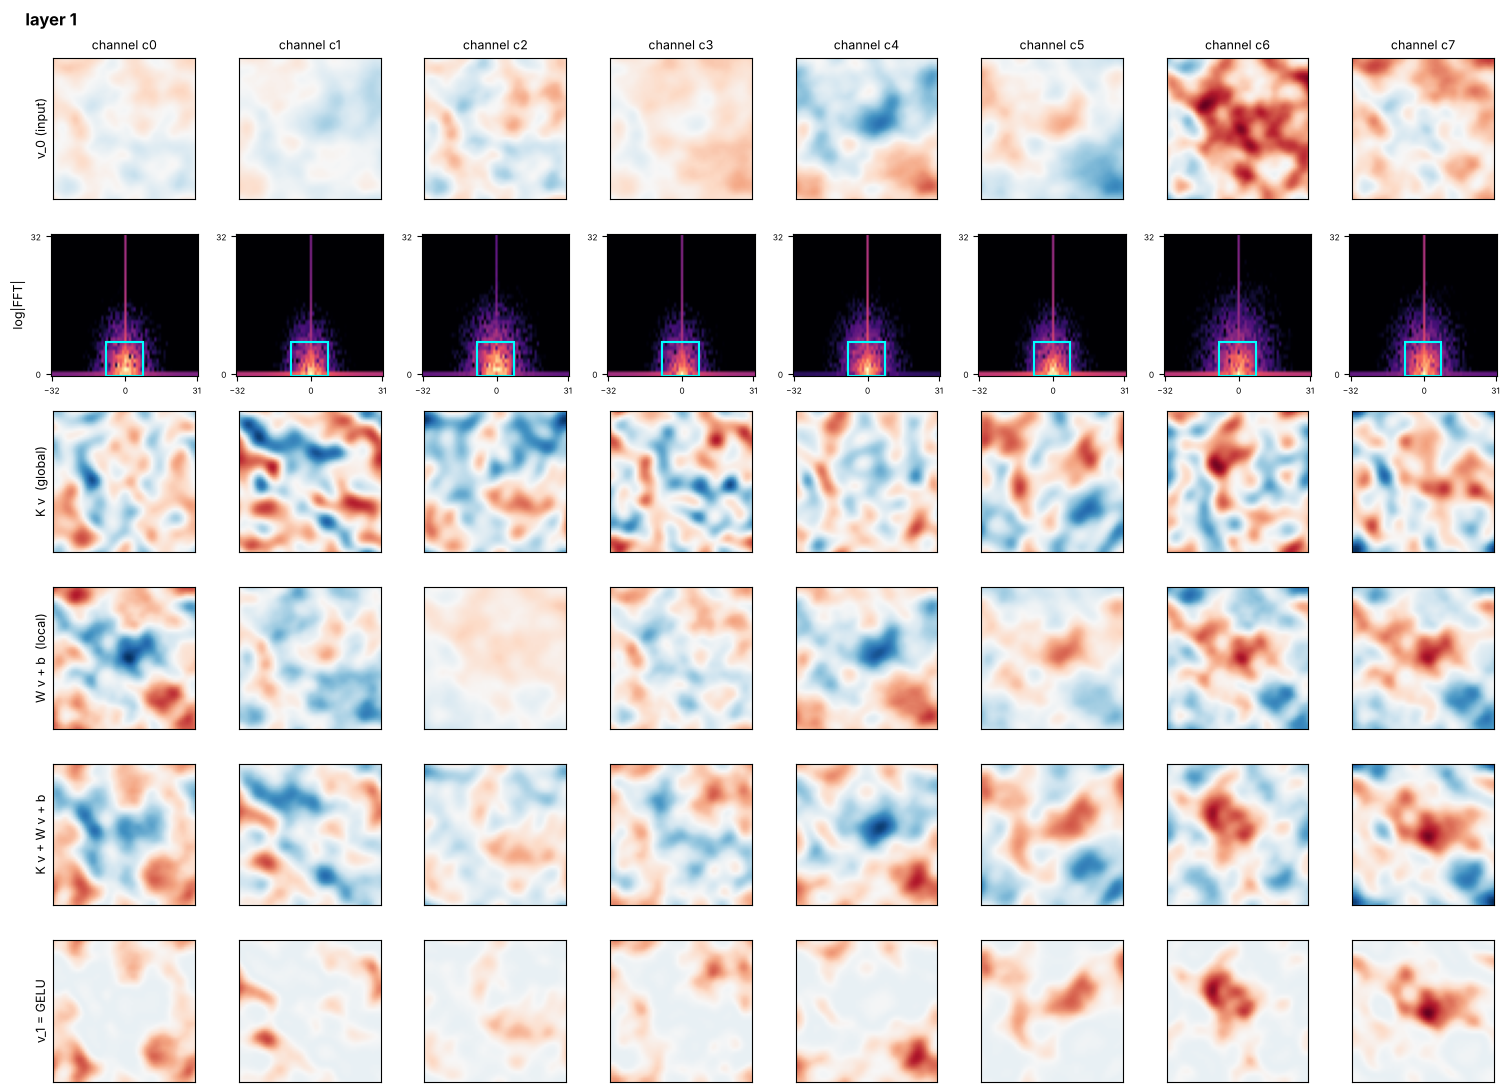

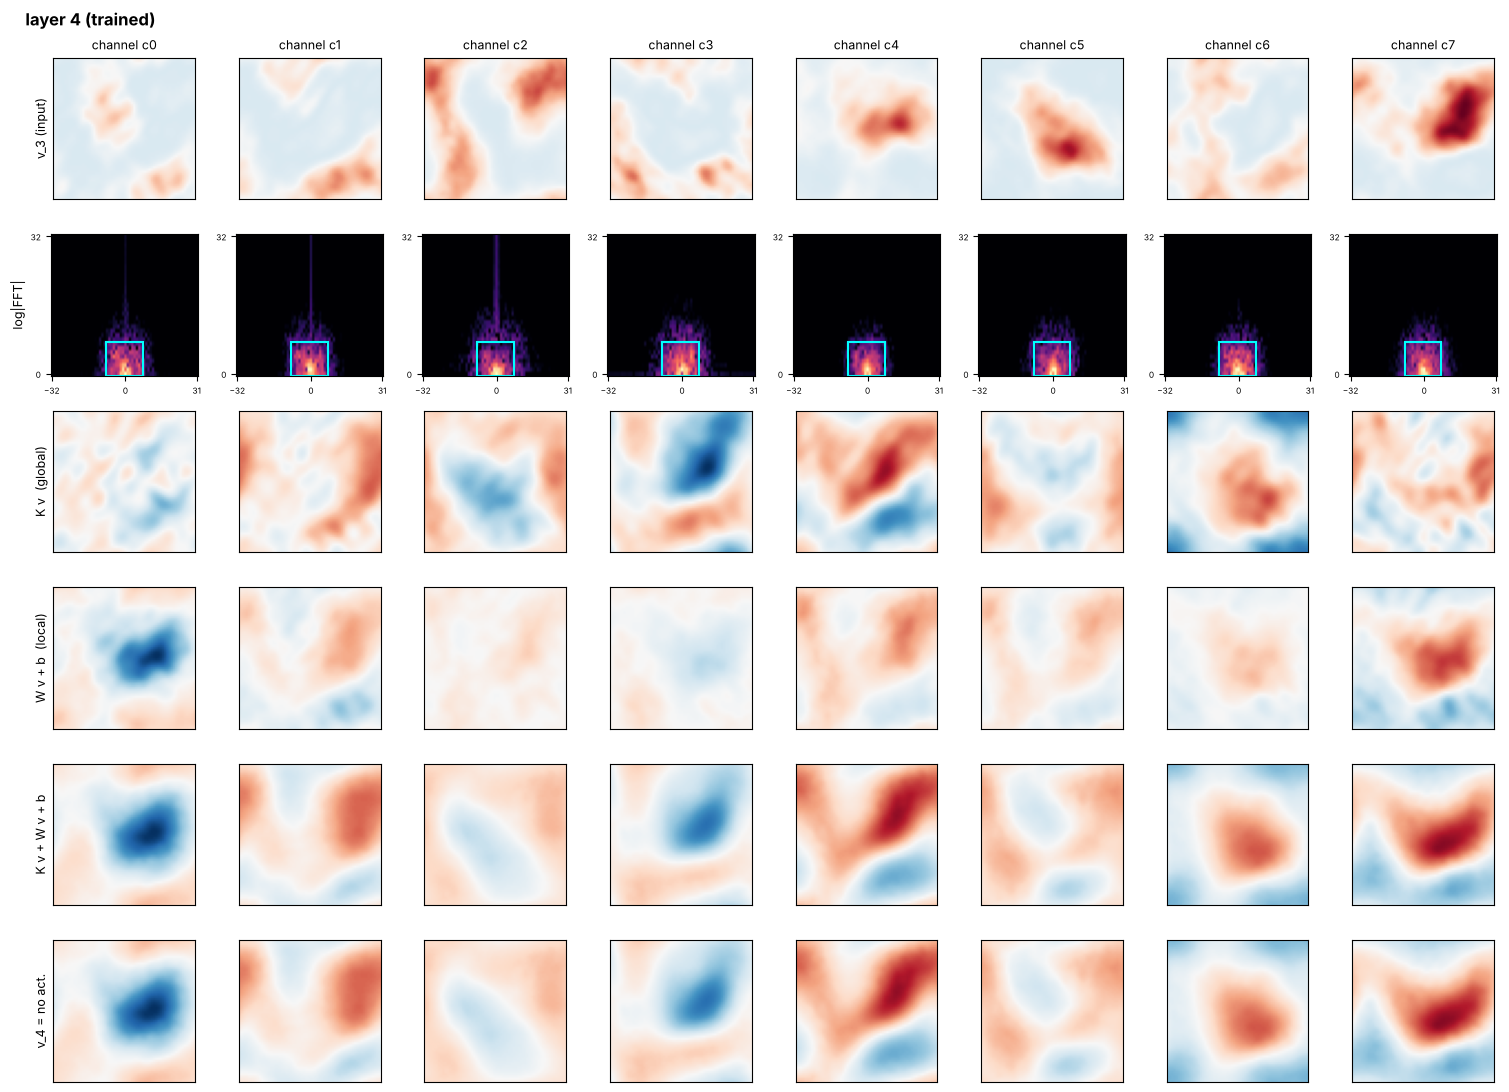

In [13]:
explore(len(snapshots) - 1, 0, 1)
viz.layer_flow_2d(fno2d.apply_with_trace(params, a_test[0]), 3, cfg.modes, "layer 4 (trained)"); plt.show()

### Predictions on unseen flows

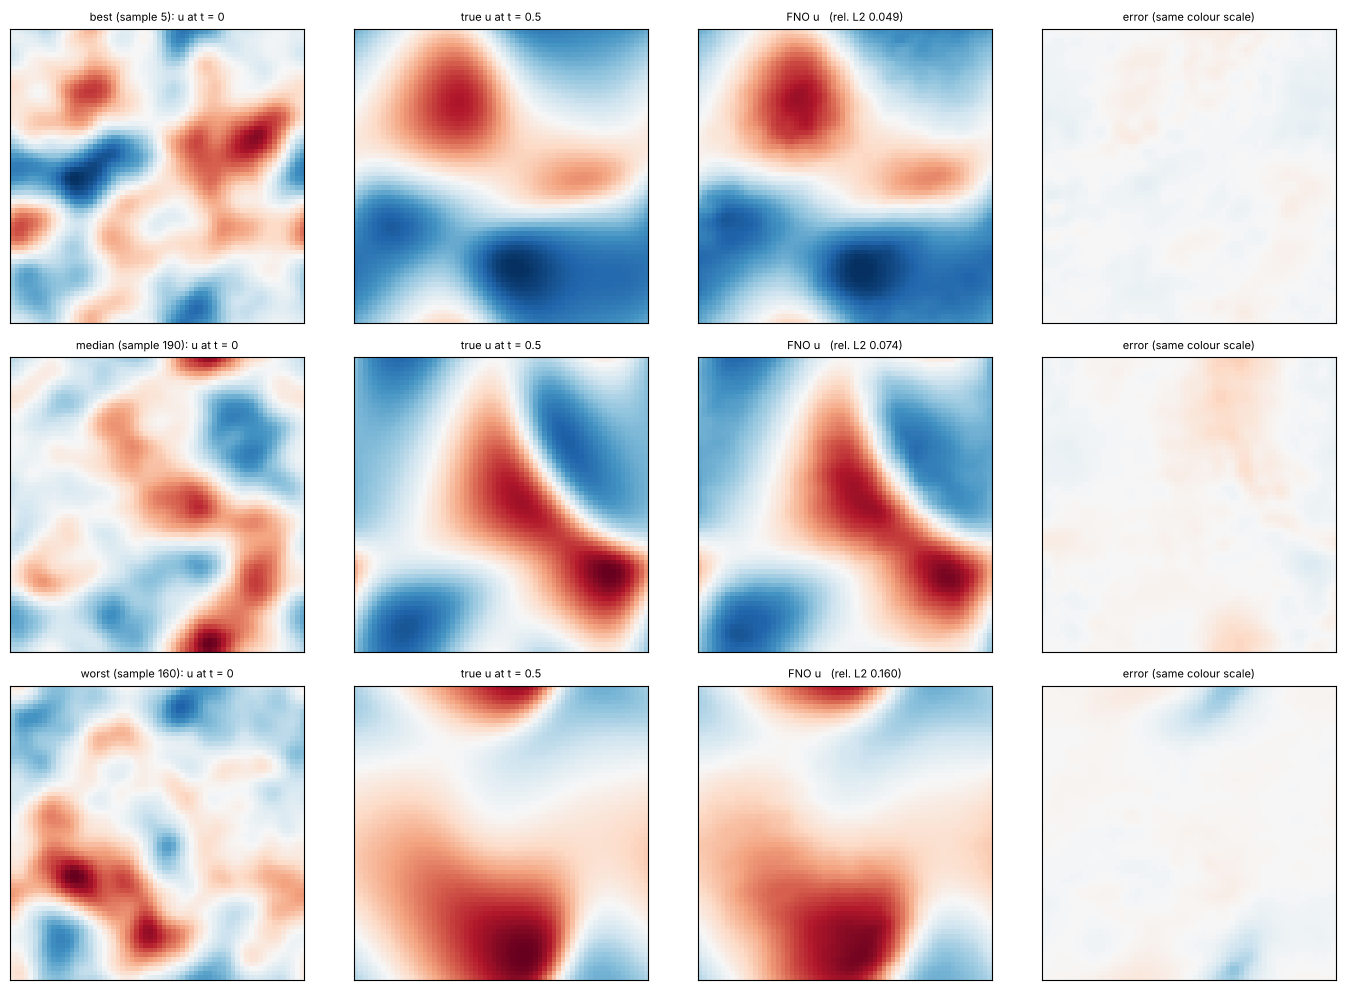

test relative L2: mean 0.079, median 0.074


In [14]:
pred = jax.vmap(fno2d.apply, in_axes=(None, 0))(params, a_test)
errs = np.asarray(jax.vmap(lambda p, u: relative_l2(p.ravel(), u.ravel()))(pred, u_test))
order = np.argsort(errs)
fig, axes = plt.subplots(3, 4, figsize=(14, 10))
for r, (i, tag) in enumerate(zip([order[0], order[len(order) // 2], order[-1]], ["best", "median", "worst"])):
    vmax = float(np.abs(u_test[i][..., 0]).max())
    viz.image(axes[r, 0], a_test[i][..., 0], f"{tag} (sample {i}): u at t = 0")
    viz.image(axes[r, 1], u_test[i][..., 0], "true u at t = 0.5", vmax=vmax)
    viz.image(axes[r, 2], pred[i][..., 0], f"FNO u   (rel. L2 {errs[i]:.3f})", vmax=vmax)
    viz.image(axes[r, 3], pred[i][..., 0] - u_test[i][..., 0], "error (same colour scale)", vmax=vmax)
plt.tight_layout(); plt.show()
print(f"test relative L2: mean {errs.mean():.3f}, median {np.median(errs):.3f}")

The remaining error is small and smooth, and largest where the velocity changes fastest. Those places need higher
frequencies, and the global path only carries $|k| < 8$; the local $W$ path and the nonlinearity have to rebuild the
rest. Widening to $d = 16$ channels brings the
test error down to about 5% (try `FNO2DConfig(width=16)`); the paper uses $d = 20$–$32$ and 12 modes.

## Takeaways

* **The input is a stack of images**, $64\times64\times4$. $P$, $W$ and $Q$ act on each pixel's channel vector with
  the same small matrix, like the GNS encoders act on each node's row.
* **The Fourier layer is the only place pixels talk to each other.** It is a learned convolution ("the same
  upstream rule everywhere") computed as one $d\times d$ multiply per kept 2D wave.
* **The FFT runs over space, per channel.** It turns each channel image into wave coefficients; FNO keeps the
  slowest $16\times8$ of them.
* **Physics enters through the data** (the solver's input/output pairs) and through the design: the same rule
  everywhere, global reach, smooth (low-mode) interactions.